## Precip Partitioning
Evaluate precipitation partitioning in forcing data.

In [1]:
%matplotlib ipympl
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
from model_datasets.forcing import LM4Forcing

In [2]:
# Load forcing - note that conda environment should have env vars set
forcing = LM4Forcing(site='Tres Ritos', forcing_string='01011010', version='0.10.1', spinup=False)

In [3]:
forcing_vars = forcing.get_variables()
forcing_vars.head()

,dimensions,long_name,units
Tair,"(time, latitude, longitude)",Near-surface air Temperature,K
Qair,"(time, latitude, longitude)",Near-surface specific humidity,kg/kg
Psurf,"(time, latitude, longitude)",Surface Pressure,Pa
Rainf,"(time, latitude, longitude)",Rainfall rate,kg/m2/s
Snowf,"(time, latitude, longitude)",Snowfall rate,kg/m2/s


In [4]:
Tair = forcing.get_data('Tair')
snow_wang = forcing.get_data('Snowf')
rain_wang = forcing.get_data('Rainf')
precip = snow_wang + rain_wang

#### E3SM Partition
See https://escomp.github.io/CTSM/release-clm5.0/tech_note/Land-Only_Mode/CLM50_Tech_Note_Land-Only_Mode.html

In [5]:
def e3sm_partition(T: pd.Series, P: pd.Series) -> tuple[pd.Series, pd.Series]:
    '''
    Partition precip using method of E3SM
    
    :param T: Air temperature in K (pandas Series)
    :param P: Precipitation (rate or total) (pandas Series)

    returns (rain, snow) as tuple of pandas Series
    '''
    # Check that inputs have the same index
    if not T.index.equals(P.index):
        raise ValueError("T and P must have the same index")
    
    # E3SM partitioning formula
    fRain = (T - 273.15) / 2
    
    # Clip fRain to be between 0 and 1
    fRain = fRain.clip(lower=0, upper=1)
    
    # Calculate snow and rain
    rain = P * fRain
    snow = P * (1 - fRain)
    
    return (rain, snow)

In [6]:
def jordan_partition(T: pd.Series, P: pd.Series) -> tuple[pd.Series, pd.Series]:
    '''
    Partition precip using method of Jordan 1991 as described in Wang 2019
    Note that NCAR NOAH-MP docs appear to have typo, while Wang makes more sense.
    Implementation here matches Wang picture.
    
    :param T: Air temperature in K (pandas Series)
    :param P: Precipitation (rate or total) (pandas Series)

    returns (rain, snow) as tuple of pandas Series
    '''
    # Check that inputs have the same index
    if not T.index.equals(P.index):
        raise ValueError("T and P must have the same index")
    
    # Change to degrees C
    Tc = T - 273.15

    # Calculate linear section first
    fSnow = -0.2*Tc + 1

    # Set sections outside of linear
    fSnow.loc[Tc < 0.5] = 1
    fSnow.loc[(Tc > 2) & (Tc < 2.5)] = 0.6
    fSnow.loc[Tc > 2.5] = 0

    # Calculate snow and rain
    snow = P * fSnow
    rain = P * (1 - fSnow)
    
    return (rain, snow)

In [7]:
rain_e3sm, snow_e3sm = e3sm_partition(Tair,precip)
rain_jordan, snow_jordan = jordan_partition(Tair,precip)

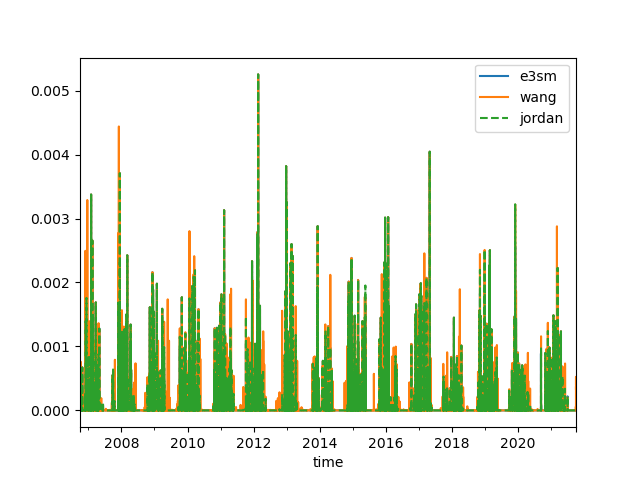

In [8]:
fig, ax = plt.subplots(1,1)

snow_e3sm.plot(ax=ax, label='e3sm')
snow_wang.plot(ax=ax, label='wang')
snow_jordan.plot(ax=ax, label='jordan', style='--')
ax.legend()

In [9]:
print('Total Snow:')
print(f'Wang: {snow_wang.sum()}')
print(f'E3SM: {snow_e3sm.sum()}')
print(f'Jordan: {snow_jordan.sum()}')

Total Snow:
Wang: 1.3112583333333334
E3SM: 0.7757086260872523
Jordan: 0.8842940896852535
